In [1]:
""" The goal of this notebook is to setp by step develop Metadynamics code for ASE.
    It will be based on the biASE calculator
    
""" 

' The goal of this notebook is to setp by step develop Metadynamics code for ASE.\n    It will be based on the biASE calculator\n    \n'

In [2]:
from biASE import General_Bias_Calculator

In [3]:
from ase.atoms import Atoms
from ase import units
from ase.io import read


from ase.md.langevin import Langevin
from ase.md.verlet import VelocityVerlet
from ase.md.velocitydistribution import MaxwellBoltzmannDistribution,Stationary, ZeroRotation
from ase.constraints import FixedPlane


import numpy as np
import matplotlib.pyplot as plt
from ase.calculators.calculator import Calculator, all_changes
from ase.io import Trajectory
import copy

from ase.calculators.mixing import LinearCombinationCalculator,MixedCalculator
import time
import jax.numpy as jnp
from jax import jit
from jax import grad ,jacfwd,jacrev


In [4]:
from Metadynamics import Metadynamics
from Metadynamics import WT_Metadynamics

In [5]:
import cmocean.cm as cmo
def plot_2d_bias(f_bias,rangeCV1=[-1,1],rangeCV2=[-1,1],N_points=100,trajectory=None,pic_name = '2D_plot.png'):
    x = np.linspace(rangeCV1[0], rangeCV1[1], N_points)
    y = np.linspace(rangeCV2[0], rangeCV2[1], N_points)

    X, Y = np.meshgrid(x, y)
    CVs=[X,Y]
    Z = f_bias(CVs)
    
    plt.contour(X, Y, Z, 50, cmap=cmo.tempo_r)#'RdGy')
    plt.colorbar()
    
    if trajectory==None:
        plt.show()
    else:
        plt.plot(trajectory[0],trajectory[1])
        plt.xlabel('x')
        plt.ylabel('y')
        plt.savefig(pic_name)
        plt.show()

def plot_1d_bias(f_bias,rangeCV1=[-0.1,1.5],N_points=100,trajectory=None,pic_name = '1D_DW_C.png'):
    x = np.linspace(rangeCV1[0], rangeCV1[1], N_points)
    
    try:
        CVs=[x] #needs to be an array for the spring method
        Z = f_bias(CVs)
        plt.plot(x, Z)
    except:
        CVs=np.array(x) #needs to be an array for the spring method
        Z = f_bias(CVs)
        plt.plot(x, Z)
    if trajectory==None:
        plt.show()
    else:
        plt.hist(trajectory[0],density=True,bins=100,range=rangeCV1)
        plt.xlabel('x')
        plt.ylabel('E')
        plt.savefig(pic_name)
        plt.show()
        

        

In [6]:
def _cvs(atom_pos):
    '''Collective variable from the x cooridinate'''
    x = atom_pos[0][0]
    return jnp.array([x])

def _cvs_2D(atom_pos):
    '''Collective variable from the x and y cooridinate'''
    x = atom_pos[0][0]
    y = atom_pos[0][1]
    return jnp.array([x,y])
"""
def _cvs(atom_pos):
    '''Collective variable from the x, y and z cooridinate'''
    x = atom_pos[0][0]
    y = atom_pos[0][1]
    z = atom_pos[0][2]
    return jnp.array([x,y,z])"""

def f_dw_cvs(cvs,scale=0.2):
    '''Double-Well'''
    x =  cvs[0]
    y =  cvs[1]
    return scale*((x**2 - 1)**2 + y**2)

def f_cvs(cvs,scale=.04):
    x = cvs[0]
    y = cvs[1]
    r = jnp.sqrt(x**2 + y**2)
    large_min = jnp.exp(-0.5*((r)/0.5)**2)
    small_mins = 0
    for i in range(5):
        x0 = 1*jnp.cos(2*jnp.pi*i/5)
        y0 = 1*jnp.sin(2*jnp.pi*i/5)
        small_mins += 1*jnp.exp(-0.5*((x-x0)**2 + (y-y0)**2)/0.2**2)

        x1 = 1.5*jnp.cos(2*jnp.pi*i/5 + jnp.pi/5)
        y1 = 1.5*jnp.sin(2*jnp.pi*i/5 + jnp.pi/5)
        small_mins += 0.8*jnp.exp(-0.2*((x-x1)**2 + (y-y1)**2)/0.2**2)

        x2=4.5*jnp.cos(2*jnp.pi*i/5 + jnp.pi/(2.5))
        y2= 4.5*jnp.sin(2*jnp.pi*i/5 + jnp.pi/(2.5))
        small_mins += 1*jnp.exp(-0.1*((x-x2)**2 + (y-y2)**2)/0.2**2)

    return scale*(-10*large_min - 10*small_mins + (x**2 +y**2))

def f_cvs_1D(cvs):
    x = cvs[0]
    return x**2*(1.-x)**2

def deriv_f_cvs_1D(cvs):
    x = cvs[0]
    df_dx = 2*x*(1.-x)*(2*x-1.)
    return np.array([[df_dx,0,0]])

def deriv_f_cvs_1D(cvs, h=1e-4):
    f0 = f_cvs_1D(cvs)
    x = cvs[0]
    fx = f_cvs_1D([x+h])
    fd = (fx - f0) / h
    return np.array([[fd,0,0]])

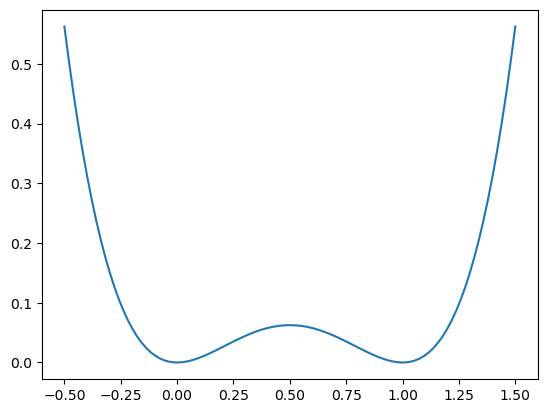

In [7]:
plot_1d_bias(f_cvs_1D,trajectory=None,rangeCV1=[-0.5,1.5])

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


[[-0.02669282 -0.01536742 -0.00580613]]
11


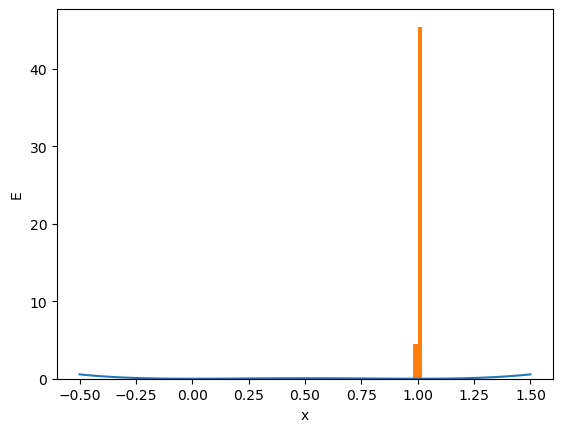

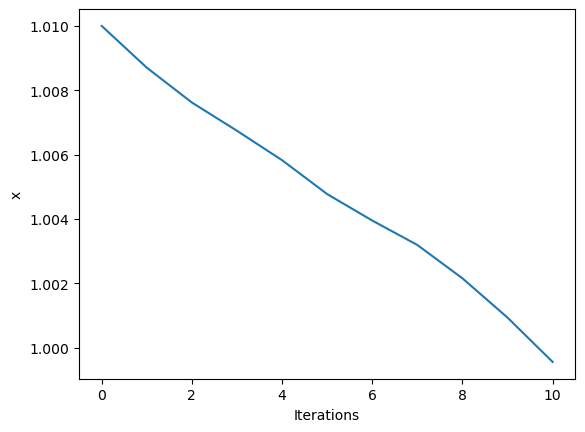

In [8]:
atoms = Atoms('C',[[1.01,0.0,0.0]])
jax_calc = General_Bias_Calculator(_cvs,f_cvs_1D)
atoms.calc = jax_calc 


MaxwellBoltzmannDistribution(atoms, temperature_K=600)
''' the first calc is thrash then but the second one looks great???
Stationary(atoms)  # zero linear momentum
ZeroRotation(atoms)  # zero angular momentum'''
print(atoms.get_velocities())
dyn = Langevin(atoms, timestep=.5 * units.fs, temperature_K=300, friction=0.1, trajectory='md.traj',fixcm=False)#Andersen(atoms, timestep=.5 * units.fs, temperature_K=3000, andersen_prob=0.01,trajectory='md.traj')#

#dyn = VelocityVerlet(atoms, timestep=1.0 * units.fs, trajectory='md.traj')

N_steps = int(1e1)
dyn.run(N_steps) 

traj = read('md.traj@::1')
print(len(traj))

#print(traj)
#print()
x = []
y = np.zeros(N_steps+1)
z = np.zeros(N_steps+1)

# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)
# Define an array to store the energy at each step
energy = np.zeros(N_steps+1)
kin = np.zeros(N_steps+1)
pot = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    x.append(xyz[0][0])
    y[i] = xyz[0][1]
    z[i] = xyz[0][2]
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    '''pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()'''
    
    
plot_1d_bias(f_cvs_1D,trajectory=[x],rangeCV1=[-0.5,1.5])

plt.xlabel('Iterations')
plt.ylabel('x')

plt.plot(x)
#plt.plot(y)
#plt.plot(z)
plt.savefig('X_movement_DW_C.png')

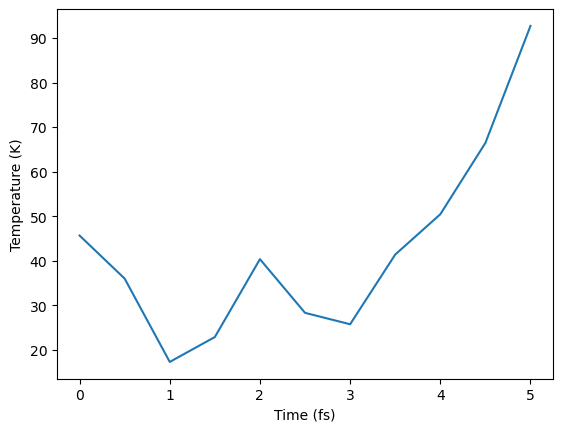

42.45559155731703


In [9]:
# Plot the temperature as a function of time
timestep = .5*units.fs
time_ = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time_, temperatures)#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.savefig('NVT_DW_temp.png')
plt.show()
print(np.average(np.array(temperatures)))

In [10]:
atoms = Atoms('C',[[1.01,0.0,0.0]])
jax_calc = General_Bias_Calculator(_cvs,f_cvs_1D)
atoms.calc = jax_calc 

'''calc1= LennardJones(rc=2.5, r0=3.0)
calc2 = LennardJones(rc=2.5, r0=3.5)
atoms.calc = LinearCombinationCalculator([calc1,calc2],[0.5,0.5])'''
from functools import partial
dyn = WT_Metadynamics(atoms, timestep=.5 * units.fs, temperature_K=0.1/units.kB, friction=1, trajectory='testing.traj'
                      ,fixcm=False,cvs=_cvs,interval_size=5,std_dev=0.1,bias_height=.05,output_file='testingit.txt',well_temp=0.1) #Langevin(atoms, timestep=.5 * units.fs, temperature_K=0.1/units.kB, friction=1, trajectory='metad.traj',fixcm=False) #
N_steps = int(1e2)
dyn.run(N_steps) 

Initial Array: None (1, 3)
0


In [ ]:
atoms = Atoms('C',[[1.01,0.0,0.0]])
jax_calc = General_Bias_Calculator(_cvs,f_cvs_1D)
atoms.calc = jax_calc 


MaxwellBoltzmannDistribution(atoms, temperature_K=600)
''' the first calc is thrash then but the second one looks great???
Stationary(atoms)  # zero linear momentum
ZeroRotation(atoms)  # zero angular momentum'''
print(atoms.get_velocities())
dyn = Metadynamics(atoms, timestep=.5 * units.fs, temperature_K=300, friction=0.1, trajectory='md.traj',fixcm=False,cvs=_cvs,interval_size=10)#Andersen(atoms, timestep=.5 * units.fs, temperature_K=3000, andersen_prob=0.01,trajectory='md.traj')#

#dyn = VelocityVerlet(atoms, timestep=1.0 * units.fs, trajectory='md.traj')

N_steps = int(1e4)
dyn.run(N_steps) 

traj = read('md.traj@::1')
print(len(traj))

#print(traj)
#print()
x = []
y = np.zeros(N_steps+1)
z = np.zeros(N_steps+1)

# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)
# Define an array to store the energy at each step
energy = np.zeros(N_steps+1)
kin = np.zeros(N_steps+1)
pot = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    x.append(xyz[0][0])
    y[i] = xyz[0][1]
    z[i] = xyz[0][2]
    
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    '''pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()'''
    
    
plot_1d_bias(f_cvs_1D,trajectory=[x],rangeCV1=[-0.5,1.5], pic_name = 'Meta_dyn_1D_DW.png')

plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(x)
#plt.plot(y)
#plt.plot(z)
#plt.savefig('X_movement_DW_C.png')

NameError: name 'Atoms' is not defined

In [ ]:
# Plot the temperature as a function of time
timestep = .5*units.fs
time_ = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time_, temperatures)#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.savefig('NVT_DW_temp.png')
plt.show()
print(np.average(np.array(temperatures)))

In [ ]:
# Here now the biased potential should be plotted

atoms = Atoms('C',[[0.0,0.0,0.0]])



Z=[]
x = np.linspace(-0.5, 1.5, 100)

for i in x:
    atoms1=copy.deepcopy(atoms)
    pos = atoms.get_positions()
    pos[0][0]+=i
    atoms1.calc = dyn.return_biased_potential()
    atoms1.set_positions(pos)
     #needs to be an array for the spring method
    Z.append(atoms1.get_potential_energy())
plt.plot(x, Z)
plt.xlabel('x')
plt.ylabel('E')
plt.savefig('biased_1D_DW_C.png')
plt.show()

In [ ]:
import random
jax_calc = General_Bias_Calculator(_cvs,f_cvs_1D)
atoms.calc = jax_calc 
pos = atoms.get_positions()

In [ ]:
%%timeit -r 5 -n 1000 
pos[0][0]+= random.uniform(0.01, 0.1)
atoms.set_positions(pos)
atoms.get_forces()

In [ ]:
atoms1.calc = dyn.return_biased_potential()

In [ ]:
%%timeit -r 5 -n 1000 
pos[0][0]+= random.uniform(0.01, 0.1)
atoms1.set_positions(pos)
atoms1.get_forces()

In [ ]:
# Here now the biased potential should be plotted

atoms = Atoms('C',[[0.0,0.0,0.0]])



Z=[]
x = np.linspace(-0.5, 1.5, 100)

for i in x:
    atoms1=copy.deepcopy(atoms)
    pos = atoms.get_positions()
    pos[0][0]+=i
    atoms1.calc = dyn.return_bias()
    atoms1.set_positions(pos)
     #needs to be an array for the spring method
    Z.append(atoms1.get_potential_energy())
plt.plot(x, Z)
plt.xlabel('x')
plt.ylabel('E')
plt.savefig('bias_1D_DW_C.png')
plt.show()

In [ ]:
import numpy as np
import jax.numpy as jnp
from jax import jit
import matplotlib.pyplot as plt

# Define the Gaussian function using numpy
def gaussian_np(x, mean, std_dev):
    """
        x (float or numpy array): Input value(s) for evaluating the Gaussian.
        mean (float or numpy array): Mean(s) of the Gaussian(s).
        std_dev (float): Standard deviation of the Gaussian(s).

    Returns:
        float or numpy array: Value(s) of the Gaussian(s) at the given input(s), summed over all means.

        this function needs to be tested!
    """
    # Ensure that mean is a 1D numpy array
    mean = np.atleast_1d(mean)

    # Evaluate the Gaussian for all means at once using numpy broadcasting
    gaussian_vals = np.exp(-0.5*((x - mean[:, jnp.newaxis])**2/(0.5*std_dev**2)))  #/ (std_dev * np.sqrt(2 * np.pi))

    # Sum over all means and return the result
    return np.sum(gaussian_vals, axis=0)
# Define the Gaussian function using JAX numpy
@jit
def gaussian_jax(x, mean, std_dev):
    
    """
        x (float or numpy array): Input value(s) for evaluating the Gaussian.
        mean (float or numpy array): Mean(s) of the Gaussian(s).
        std_dev (float): Standard deviation of the Gaussian(s).

    Returns:
        float or numpy array: Value(s) of the Gaussian(s) at the given input(s), summed over all means.


        this function needs to be tested!
    """
    # Ensure that mean is a 1D numpy array
    mean = jnp.atleast_1d(mean)

    # Evaluate the Gaussian for all means at once using numpy broadcasting
    gaussian_vals = jnp.exp(-0.5*((x - mean[:, jnp.newaxis])**2/(0.5*std_dev**2))) 

    # Sum over all means and return the result
    print(jnp.sum(gaussian_vals, axis=0))
    return jnp.sum(gaussian_vals, axis=0)

# Define the means and standard deviations to use
means = np.array([-2, -1, 0, 1, 2])
sigmas = np.array([0.5, 1, 2])

# Generate x values to evaluate the Gaussian functions at
x = np.linspace(-5, 5, 500)

# Evaluate the Gaussian functions at each set of means and standard deviations
gaussians_np = np.zeros((len(sigmas), len(means), len(x)))
for i, sigma in enumerate(sigmas):
    for j, mean in enumerate(means):
        gaussians_np[i, j] = gaussian_np(x, mean, sigma)

gaussians_jax = np.zeros((len(sigmas), len(means), len(x)))
for i, sigma in enumerate(sigmas):
    for j, mean in enumerate(means):
        gaussians_jax[i, j] = np.asarray(gaussian_jax(x, mean, sigma))

# Plot the Gaussian functions
for i, sigma in enumerate(sigmas):
    for j, mean in enumerate(means):
        plt.plot(x, gaussians_np[i, j], label=f"Mean = {mean}")
    plt.title(f"Gaussian Functions with Std Dev = {sigma}")
    plt.legend()
    plt.show()
    for j, mean in enumerate(means):
        plt.plot(x, gaussians_jax[i, j], label=f"Mean = {mean}")
    plt.title(f"Gaussian Functions with Std Dev = {sigma} from the Jax code")
    plt.legend()
    plt.show()

    
# Plot the Gaussian functions
for i, sigma in enumerate(sigmas):
    for j, mean in enumerate(means):
        plt.plot(x, gaussians_np[i, j], label=f"Mean = {mean}")
        plt.plot(x, gaussians_jax[i, j], label=f"Mean_jax = {mean}")
    plt.title(f"Gaussian Functions with Std Dev = {sigma}")
    plt.legend()
    plt.show()

       



In [ ]:
import jax.numpy as jnp
from jax import jit
import matplotlib.pyplot as plt

# Define the Gaussian function using JAX
@jit
def gaussian_jax(x, mean, std_dev):
    mean = jnp.atleast_1d(mean)
    gaussian_vals = jnp.exp(-0.5*((x - mean[:, jnp.newaxis])**2/(0.5*std_dev**2)))
    return jnp.sum(gaussian_vals, axis=0)

# Define the inputs
x = jnp.linspace(-5, 5, 1000)
means = jnp.array([-2, -1, 0, 1, 2])
std_dev = 1

# Compute the sum of all 5 Gaussians
gaussian_sum = gaussian_jax(x, means, std_dev)

# Plot the result
plt.plot(x, gaussian_sum)
plt.xlabel('x')
plt.ylabel('Gaussian sum')
plt.show()


In [ ]:
#checks is the [0] is necessary and what it does
def gaussian_1D(cvs,mean_cvs,std_dev): ### here with jax numpy
        """ 
        x (float or numpy array): Input value(s) for evaluating the Gaussian.
            mean (float or numpy array): Mean(s) of the Gaussian(s).
            std_dev (float): Standard deviation of the Gaussian(s).

        Returns:
            float or numpy array: Value(s) of the Gaussian(s) at the given input(s), summed over all means.
            
            
            this function needs to be tested! seems to be the same as the above numpy version but forces need to be tested
        """ 
        x = cvs[0]

        # Evaluate the Gaussian for all means at once using numpy broadcasting
        gaussian_vals = jnp.exp(-0.5*((x - mean_cvs[:, jnp.newaxis])**2/(0.5*std_dev**2))) 
        
        # Sum over all means and return the result
        #print(jnp.sum(gaussian_vals, axis=0)[0])
        return jnp.sum(gaussian_vals, axis=0)[0]
    
x = [1]
means = jnp.array([-2, -1, 0, 1, 2])
std_dev = 1
print(gaussian_1D(x,means,std_dev))
print(gaussian_1D(x,np.array([means[0]]),std_dev))
print(gaussian_1D(x,np.array([means[1]]),std_dev))
print(gaussian_1D(x,np.array([means[2]]),std_dev))
print(gaussian_1D(x,np.array([means[3]]),std_dev))
print(gaussian_1D(x,np.array([means[4]]),std_dev))
print(gaussian_1D(x,np.array([means[0]]),std_dev)+gaussian_1D(x,np.array([means[1]]),std_dev)+gaussian_1D(x,np.array([means[2]]),std_dev)+gaussian_1D(x,np.array([means[3]]),std_dev)+gaussian_1D(x,np.array([means[4]]),std_dev))

In [ ]:
def gaussian_2D(cvs,mean_cvs,std_dev):
    """
        x (float or numpy array): Input value(s) for evaluating the Gaussian.
        mean (float or numpy array): Mean(s) of the Gaussian(s).
        std_dev (float): Standard deviation of the Gaussian(s).

    Returns:
        float or numpy array: Value(s) of the Gaussian(s) at the given input(s), summed over all means.


        this function needs to be tested! seems to be the same as the above numpy version but forces need to be tested
    """
    x, y = cvs
    # Evaluate the Gaussian for all means at once using numpy broadcasting
    gaussian_vals = jnp.exp(-0.5*((x - mean_cvs[:, 0])**2/(0.5*std_dev**2)) \
                                                  - 0.5*((y - mean_cvs[:, 1])**2/(0.5*std_dev**2)))

    # Sum over all means and return the result
    #print(jnp.sum(gaussian_vals, axis=0)[0])
    return jnp.sum(gaussian_vals,axis=0)#[0] 
    
cvs = [1,1]
means = jnp.array([[-2,-2], [-1,-1], [0,0], [1,1], [2,2]])
std_dev = 1
print(gaussian_2D(cvs,means,std_dev))
print(gaussian_2D(cvs,np.array([means[0]]),std_dev))
print(gaussian_2D(cvs,np.array([means[1]]),std_dev))
print(gaussian_2D(cvs,np.array([means[2]]),std_dev))
print(gaussian_2D(cvs,np.array([means[3]]),std_dev))
print(gaussian_2D(cvs,np.array([means[4]]),std_dev))
print(gaussian_2D(cvs,np.array([means[0]]),std_dev)+gaussian_2D(cvs,np.array([means[1]]),std_dev)+gaussian_2D(cvs,np.array([means[2]]),std_dev)+gaussian_2D(cvs,np.array([means[3]]),std_dev)+gaussian_2D(cvs,np.array([means[4]]),std_dev))

In [ ]:
import numpy as np

array1 = np.array([[[1.00334198e+00, 1.21695564e-05, 1.71182510e-04]], [[1, 1, 1]]])
array2 = np.array([[1.00680065e+00, 6.39768361e-05, 3.07198859e-04]])

combined_array = np.concatenate((array1, np.expand_dims(array2, axis=0)))

print(combined_array)


# It is time for trying some of the 2D stuff!

In [ ]:
atoms = Atoms('C',[[-1.0,0.0,0.0]])

jax_calc = General_Bias_Calculator(_cvs_2D,f_cvs)
atoms.calc = jax_calc 


c = FixedPlane(
    [0],
    [0, 0, 1],
)

#atoms.set_constraint(c)


MaxwellBoltzmannDistribution(atoms, temperature_K=700)
print(atoms.get_velocities())

dyn = Langevin(atoms, timestep=0.5 * units.fs, temperature_K=450, friction=.1,trajectory='md.traj',fixcm=False)

#dyn = VelocityVerlet(atoms, timestep=1.0 * units.fs, trajectory='md.traj')

N_steps = int(1e5)
dyn.run(N_steps) 

In [ ]:
traj = read('md.traj@:')
print(len(traj))
#print(traj)
#print()
# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)

x = np.zeros(N_steps+1)
y = np.zeros(N_steps+1)
z = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    x[i] = xyz[0][0]
    y[i] = xyz[0][1]
    z[i] = xyz[0][2]
    
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()


plot_2d_bias(f_cvs,trajectory=[x,y],rangeCV1=[-3,3],rangeCV2=[-3,3])

In [ ]:
plt.plot(x)
plt.plot(y)
plt.plot(z)
plt.xlabel('Iterations')
plt.ylabel('x')
plt.savefig('Coordinates_2D_plot.png')

In [ ]:
# Plot the temperature as a function of time
timestep = .5*units.fs
time_ = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time_, temperatures)#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.savefig('NVT_DW_temp.png')
plt.show()
print(np.average(np.array(temperatures)))

## Now we try the Metadynamics code with this

In [ ]:
atoms = Atoms('C',[[-1.0,0.0,0.0]])

jax_calc = General_Bias_Calculator(_cvs_2D,f_cvs)
atoms.calc = jax_calc 


c = FixedPlane(
    [0],
    [0, 0, 1],
)

#atoms.set_constraint(c)


MaxwellBoltzmannDistribution(atoms, temperature_K=700)
''' the first calc is thrash then but the second one looks great???
Stationary(atoms)  # zero linear momentum
ZeroRotation(atoms)  # zero angular momentum'''
print(atoms.get_velocities())
dyn = Metadynamics(atoms, timestep=.5 * units.fs, temperature_K=350, friction=.1, trajectory='metad.traj',fixcm=False,cvs=_cvs_2D,interval_size=10)#Andersen(atoms, timestep=.5 * units.fs, temperature_K=3000, andersen_prob=0.01,trajectory='md.traj')#

#dyn = VelocityVerlet(atoms, timestep=1.0 * units.fs, trajectory='md.traj')

N_steps = int(1e5)
dyn.run(N_steps) 

traj = read('metad.traj@::1')
print(len(traj))

#print(traj)
#print()
x = []
y = np.zeros(N_steps+1)
z = np.zeros(N_steps+1)

# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)
# Define an array to store the energy at each step
energy = np.zeros(N_steps+1)
kin = np.zeros(N_steps+1)
pot = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    x.append(xyz[0][0])
    y[i] = xyz[0][1]
    z[i] = xyz[0][2]
    
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    '''pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()'''
    
    

plot_2d_bias(f_cvs,trajectory=[x,y],rangeCV1=[-3,3],rangeCV2=[-3,3],pic_name='Metadyn_flower_well.png')

plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(x)
plt.plot(y)
plt.plot(z)
#plt.savefig('X_movement_DW_C.png')

In [ ]:
# Plot the temperature as a function of time
timestep = .5*units.fs
time_ = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time_, temperatures)#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.savefig('NVT_DW_temp.png')
plt.show()
print(np.average(np.array(temperatures)))

In [ ]:
# Here now the biased potential should be plotted

atoms = Atoms('C',[[0.0,0.0,0.0]])



Z=[]
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)
CVs=[X,Y]
for j in y:
    for i in x:
        atoms1=copy.deepcopy(atoms)
        pos = atoms.get_positions()
        pos[0][0]+=i
        pos[0][1]+=j
        atoms1.calc = dyn.return_biased_potential()
        atoms1.set_positions(pos)
         #needs to be an array for the spring method
        Z.append(atoms1.get_potential_energy())
Z=np.array(Z).reshape(100,100)
print(X.shape,Y.shape,len(Z))
plt.xlabel('x')
plt.ylabel('y')
plt.contour(X, Y, Z, 50, cmap='RdGy')
plt.colorbar()
plt.savefig('Biased_2D.png')
plt.show()

In [ ]:
# Here now the biased potential should be plotted

atoms = Atoms('C',[[0.0,0.0,0.0]])



Z=[]
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)
CVs=[X,Y]
for j in y:
    for i in x:
        atoms1=copy.deepcopy(atoms)
        pos = atoms.get_positions()
        pos[0][0] +=i
        pos[0][1] +=j
        atoms1.calc = dyn.return_bias()
        atoms1.set_positions(pos)
        #needs to be an array for the spring method
        Z.append(atoms1.get_potential_energy())
Z=np.array(Z).reshape(100,100)
print(X.shape,Y.shape,len(Z))
plt.xlabel('x')
plt.ylabel('y')
plt.contour(X, Y, Z, 50, cmap='RdGy')
plt.colorbar()
plt.savefig('Bias_2D.png')
plt.show()

In [ ]:
from ase.build import fcc100, add_adsorbate
from ase.optimize import FIRE,BFGS
from ase.calculators.lammpsrun import LAMMPS

from ase.constraints import FixAtoms,FixedLine

In [ ]:
def _distance(atom_pos):
    return jnp.array([jnp.sqrt(sum((atom_pos[75]-atom_pos[76])**2))])

In [ ]:
initial = fcc100('Pd', size=(5, 5, 3), vacuum=10.0)
dimer = fcc100('Pd', size=(2, 1, 1), vacuum=10.0)
add_adsorbate(initial, dimer, 1.611, position=(4,4))
files = ['Pd_u3.eam']
lammps = LAMMPS(files=files)
lammps.set(pair_style='eam',pair_coeff=['* * Pd_u3.eam'],atom_style='charge',units='metal')
mask = [atom.tag > 2 for atom in initial]
constraint = FixAtoms(mask=mask)
initial.set_constraint(constraint)
initial.calc = lammps

In [ ]:
FIRE(initial).run(fmax=0.05)
constraint = FixedLine([75,76], [1, 0, 0])
initial.set_constraint(constraint)

      Step     Time          Energy         fmax
*Force-consistent energies used in optimization.
FIRE:    0 19:09:26     -266.804313*       1.0889
FIRE:    1 19:09:26     -266.874182*       0.9489
FIRE:    2 19:09:26     -266.992723*       0.7028
FIRE:    3 19:09:26     -267.129775*       0.5218
FIRE:    4 19:09:26     -267.261770*       0.5017
FIRE:    5 19:09:26     -267.379973*       0.5435
FIRE:    6 19:09:26     -267.487423*       0.5724
FIRE:    7 19:09:26     -267.591094*       0.4995
FIRE:    8 19:09:26     -267.699309*       0.4067
FIRE:    9 19:09:26     -267.796984*       0.3313
FIRE:   10 19:09:26     -267.856971*       0.3610
FIRE:   11 19:09:26     -267.864666*       0.3407
FIRE:   12 19:09:26     -267.868095*       0.3217
FIRE:   13 19:09:26     -267.874175*       0.2866
FIRE:   14 19:09:26     -267.881571*       0.2405
FIRE:   15 19:09:26     -267.888786*       0.1916
FIRE:   16 19:09:26     -267.894658*       0.1605
FIRE:   17 19:09:26     -267.898619*       0.1404
FI

/home/goennheimer/miniconda3/envs/SOAP_j_env/lib/python3.10/site-packages/ase/calculators/lammpsrun.py:379: UserWarning: semi-periodic ASE cell detected - translation to proper LAMMPS input cell might fail
  warnings.warn(


In [ ]:
"""%%time
MaxwellBoltzmannDistribution(initial, temperature_K=600)
#print(initial.get_velocities())

dyn = Langevin(initial, timestep=1 * units.fs, temperature_K=300, friction=1,trajectory='md.traj',fixcm=False)


N_steps = int(5e3)
dyn.run(N_steps) """

"%%time\nMaxwellBoltzmannDistribution(initial, temperature_K=600)\n#print(initial.get_velocities())\n\ndyn = Langevin(initial, timestep=1 * units.fs, temperature_K=300, friction=1,trajectory='md.traj',fixcm=False)\n\n\nN_steps = int(5e3)\ndyn.run(N_steps) "

In [ ]:
%%time
timestep = 0.002
#print(initial.get_velocities())
#MaxwellBoltzmannDistribution(initial, temperature_K=600)
mom = initial.get_momenta()
mom[75]=[-1.1,0,0]
mom[76] = [1.1,0,0]
initial.set_momenta(mom)
dyn = WT_Metadynamics(initial, timestep=timestep, temperature_K=0.05/units.kB, friction=.1, trajectory='metad_dimer.traj',fixcm=False,
                   cvs=_distance,std_dev=0.2,bias_height=.1 ,interval_size=100,output_file='test_dimer.txt',well_temp=0.05)

N_steps = int(50000)
dyn.run(N_steps) 

Initial Array: None (77, 3)
0
CPU times: user 4min 51s, sys: 15 s, total: 5min 6s
Wall time: 6min 6s


True

In [ ]:
atoms1=Trajectory('metad_dimer.traj')[-1]
print(_distance(atoms1.get_positions()))
atoms2=Trajectory('PL_dimer.traj')[-1]
print(_distance(atoms2.get_positions()))

[2.6273923]
[10.257128]


In [ ]:
# Here now the biased potential should be plotted

initial.calc=None


Z=[]
x = np.linspace(-2.5, 10, 1000)

for i in x:
    atoms1=copy.deepcopy(initial)
    pos = initial.get_positions()
    pos[76][0]+=i
    atoms1.calc = dyn.return_bias()
    atoms1.set_positions(pos)
     #needs to be an array for the spring method
    Z.append(atoms1.get_potential_energy())
plt.plot((x +2.6472), Z)
plt.xlabel('d')
plt.ylabel('E')
#plt.savefig('.png')
plt.show()

In [ ]:
traj = read('metad.traj@::1')
print(len(traj))


scm = np.zeros(N_steps+1)
tcm = np.zeros(N_steps+1)

# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)
# Define an array to store the energy at each step
energy = np.zeros(N_steps+1)
kin = np.zeros(N_steps+1)
pot = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    #print(i)
    #print(snap.calc)
    xyz = snap.get_positions()
    scm[i],tcm[i] =_cvs_moments(xyz,cutoff=1.5)
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
    
# Plot the temperature as a function of time
timestep = .5*units.fs
time_ = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time_, temperatures)#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.savefig('NVT_DW_temp.png')
plt.show()
print(np.average(np.array(temperatures)))


plt.xlabel('Iterations')
plt.ylabel('Energy')
#plt.plot(kin)
plt.plot(pot)
#plt.plot(energy)

In [ ]:
print(np.sqrt(sum((initial.get_positions()[75]-initial.get_positions()[76])**2)))

In [ ]:
import numpy as np
from scipy.stats import moment

def get_coordination_numbers(atoms, cutoff):
    """
    Compute coordination numbers for all atoms in an ASE Atoms object.
    """
    # Get distances between all atoms
    distances = atoms.get_all_distances(mic=True)
    # Get indices of neighboring atoms within the cutoff distance
    indices = np.argwhere(distances <= cutoff)
    # Count number of neighbors for each atom
    coordination_numbers = np.zeros(len(atoms))
    for i in range(len(atoms)):
        coordination_numbers[i] = np.sum(indices[:, 0] == i)
    return coordination_numbers

def get_moments(coordination_numbers):
    """
    Compute the second and third central moments of the distribution of
    coordination numbers.
    """
    scm = moment(coordination_numbers, moment=2)
    tcm = moment(coordination_numbers, moment=3)
    return scm, tcm


In [ ]:
from ase.build import bulk

# Create a simple cubic copper crystal
cu = bulk('Cu', cubic=True)

# Compute coordination numbers
cutoff = 3.0  # Å
cn = get_coordination_numbers(cu, cutoff)

print(cn)
# Compute moments
scm, tcm = get_moments(cn)

print(f"SCM: {scm}")
print(f"TCM: {tcm}")


[4. 4. 4. 4.]
SCM: 0.0
TCM: 0.0


In [ ]:
import numpy as np
from scipy.stats import moment
from ase import Atoms
from ase.build import molecule
from ase.neighborlist import neighbor_list

def get_coordination_numbers(atoms, cutoff=3.0):
    """Calculate coordination numbers for all atoms in an ASE Atoms object."""
    nl = neighbor_list('ijd', atoms, cutoff)
    return np.bincount(nl[0], minlength=len(atoms))

def get_coordination_moments_numpy(coord_nums):
    """Calculate the second and third central moments of the coordination number distribution using numpy."""
    mean = np.mean(coord_nums)
    scm = np.sum((coord_nums - mean)**2) / len(coord_nums)
    tcm = np.sum((coord_nums - mean)**3) / len(coord_nums)
    return scm, tcm

def get_coordination_moments_scipy(coord_nums):
    """Calculate the second and third central moments of the coordination number distribution using scipy."""
    mean = np.mean(coord_nums)
    scm = moment(coord_nums, moment=2)
    tcm = moment(coord_nums, moment=3)
    return scm, tcm

# Create water molecule
water = molecule('H2O2')
#water.positions += [0.0, 0.0, 2.0]  # shift to avoid periodic boundary effects

# Calculate coordination numbers
coord_nums = get_coordination_numbers(water, cutoff=1.5)

print(coord_nums)
# Calculate moments using numpy
scm_numpy, tcm_numpy = get_coordination_moments_numpy(coord_nums)
print(f"Second central moment (numpy): {scm_numpy:.2f}")
print(f"Third central moment (numpy): {tcm_numpy:.2f}")

# Calculate moments using scipy
scm_scipy, tcm_scipy = get_coordination_moments_scipy(coord_nums)
print(f"Second central moment (scipy): {scm_scipy:.2f}")
print(f"Third central moment (scipy): {tcm_scipy:.2f}")


[2 2 1 1]
Second central moment (numpy): 0.25
Third central moment (numpy): 0.00
Second central moment (scipy): 0.25
Third central moment (scipy): 0.00


In [ ]:
def get_coordination_numbers(atoms_positions, cutoff):
    dist_matrix = np.sqrt(np.sum((atoms_positions[:, np.newaxis] - atoms_positions) ** 2, axis=-1))
    return np.sum((dist_matrix <= cutoff) & (dist_matrix > 0), axis=-1)

'''def get_coordination_numbers(atoms_positions, cutoff):
    """Based on the paper"""
    dist_matrix = np.sqrt(np.sum((atoms_positions[:, np.newaxis] - atoms_positions) ** 2, axis=-1))
    print(dist_matrix)
    coordination_numbers = np.zeros(len(atoms_positions), dtype=float)
    print(coordination_numbers)
    for i in range(len(atoms_positions)):
        for j in range(len(atoms_positions)):
            if i != j:
                r_ij = dist_matrix[i, j]
                #print("rij",r_ij)
                x_ij = (1 - (r_ij / cutoff) ** 8) / (1 - (r_ij / cutoff) ** 16)
                #print("xij",x_ij)
                coordination_numbers[i] += x_ij
                #print(coordination_numbers[i])
    return coordination_numbers'''

def get_coordination_numbers(atoms_positions, cutoff):
    dist_matrix = np.sqrt(np.sum((atoms_positions[:, np.newaxis] - atoms_positions) ** 2, axis=-1))
    x_matrix = (1 - (dist_matrix / cutoff) ** 8) / (1 - (dist_matrix / cutoff) ** 16)
    print(x_matrix)
    np.fill_diagonal(x_matrix, 0)  # Set diagonal elements to zero
    coordination_numbers = np.sum(x_matrix, axis=1)
    return coordination_numbers


def get_coordination_moments_numpy(coord_nums):
    """Calculate the second and third central moments of the coordination number distribution using numpy."""
    mean = np.mean(coord_nums)
    scm = np.sum((coord_nums - mean)**2) / len(coord_nums)
    tcm = np.sum((coord_nums - mean)**3) / len(coord_nums)
    return scm, tcm

# Create water molecule
water = molecule('H2O')
#water.positions += [0.0, 0.0, 2.0]  # shift to avoid periodic boundary effects

# Calculate coordination numbers
coord_nums = get_coordination_numbers(water.get_positions(), cutoff=1.5)
print(coord_nums,)
# Calculate moments using numpy
scm_numpy, tcm_numpy = get_coordination_moments_numpy(coord_nums)
print(f"Second central moment (numpy): {scm_numpy:.2f}")
print(f"Third central moment (numpy): {tcm_numpy:.2f}")


# Calculate moments using scipy
scm_scipy, tcm_scipy = get_coordination_moments_scipy(coord_nums)
print(f"Second central moment (scipy): {scm_scipy:.2f}")
print(f"Third central moment (scipy): {tcm_scipy:.2f}")



[[1.         0.97066609 0.97066609]
 [0.97066609 1.         0.46506101]
 [0.97066609 0.46506101 1.        ]]
[1.94133217 1.4357271  1.4357271 ]
Second central moment (numpy): 0.06
Third central moment (numpy): 0.01
Second central moment (scipy): 0.06
Third central moment (scipy): 0.01


In [ ]:
import jax
import jax.numpy as jnp
import ase
def fill_diagonal(matrix, value):
    num_rows, num_cols = matrix.shape
    diagonal_indices = jnp.arange(min(num_rows, num_cols))
    filled_matrix = jax.ops.index_update(matrix, (diagonal_indices, diagonal_indices), value)
    return filled_matrix

def _cvs_moments(atoms_positions, cutoff):
    """ Calculate coordination numbers for all atoms in an ASE Atoms object.
        And then calculate the second and third central moments of the coordination number distribution using numpy.
    """
    dist_matrix = jnp.sqrt(jnp.sum((atoms_positions[:, jnp.newaxis] - atoms_positions) ** 2, axis=-1))
    x_matrix = (1 - (dist_matrix / cutoff) ** 8) / (1 - (dist_matrix / cutoff) ** 16)
    #print(x_matrix.shape[0])
    x_matrix = x_matrix.at[jnp.diag_indices(x_matrix.shape[0])].set(0) # there is no jnp.fill_diagonal(x_matrix, 0)  # Set diagonal elements to zero
    coord_nums = jnp.sum(x_matrix, axis=1)
    #print(coord_nums)
    mean = jnp.mean(coord_nums)
    scm = jnp.sum((coord_nums - mean)**2) / len(coord_nums)
    tcm = jnp.sum((coord_nums - mean)**3) / len(coord_nums)
    #print(scm, tcm)
    return scm, tcm

# Create water molecule
water = molecule('H2O')
#water.positions += [0.0, 0.0, 2.0]  # shift to avoid periodic boundary effects


scm_numpy, tcm_numpy = _cvs_moments(water.get_positions(), cutoff=1.0)
print(f"Second central moment (numpy): {scm_numpy:.2f}")
print(f"Third central moment (numpy): {tcm_numpy:.2f}")

atoms = read('isomer.xyz')
cons = [FixedPlane(i, [0, 0, 1]) for i in range(7)]
scm_numpy, tcm_numpy = _cvs_moments(atoms.get_positions(), cutoff=1.5)
print(f"Second central moment (numpy): {scm_numpy:.2f}")
print(f"Third central moment (numpy): {tcm_numpy:.2f}")


Second central moment (numpy): 0.06
Third central moment (numpy): 0.01
Second central moment (numpy): 0.76
Third central moment (numpy): 1.34


In [ ]:
def plot_2d_bias(trajectory=None,pic_name = '2D_plot.png'):
    plt.plot(trajectory[0],trajectory[1])
    plt.xlabel('scm')
    plt.ylabel('tcm')
    plt.savefig(pic_name)
    plt.show()

In [ ]:
cons = [FixedPlane(i, [0, 0, 1]) for i in range(7)]
print(cons)

[FixedPlane(indices=[0], [0.0, 0.0, 1.0]), FixedPlane(indices=[1], [0.0, 0.0, 1.0]), FixedPlane(indices=[2], [0.0, 0.0, 1.0]), FixedPlane(indices=[3], [0.0, 0.0, 1.0]), FixedPlane(indices=[4], [0.0, 0.0, 1.0]), FixedPlane(indices=[5], [0.0, 0.0, 1.0]), FixedPlane(indices=[6], [0.0, 0.0, 1.0])]


In [ ]:
from ase import units
from ase.io import read
from ase.constraints import FixedPlane
from ase.calculators.lj import LennardJones

In [ ]:

timestep = 0.005
#.5 * units.fs
atoms = read('isomer.xyz')
print(_cvs_moments(atoms.get_positions(), cutoff=1.5))
print(atoms.get_velocities())
cons = [FixedPlane(i, [0, 0, 1]) for i in range(7)]
atoms.set_constraint(cons)
atoms.set_masses([1, 1, 1, 1, 1, 1, 1])
atoms.calc = LennardJones(rc=2.5, r0=3.0)
'''calc1= LennardJones(rc=2.5, r0=3.0)
calc2 = LennardJones(rc=2.5, r0=3.5)
atoms.calc = LinearCombinationCalculator([calc1,calc2],[0.5,0.5])'''
from functools import partial
dyn = WT_Metadynamics(atoms, timestep=timestep, temperature_K=0.1/units.kB, friction=1, trajectory='metad3.traj'
                      ,fixcm=False,cvs=partial(_cvs_moments, cutoff=1.5),interval_size=500,std_dev=0.1,bias_height=.05,output_file='test3.txt',well_temp=0.1) #Langevin(atoms, timestep=.5 * units.fs, temperature_K=0.1/units.kB, friction=1, trajectory='metad.traj',fixcm=False) #
N_steps = int(5e5)
dyn.run(N_steps) 

(DeviceArray(0.7579546, dtype=float32), DeviceArray(1.3357965, dtype=float32))
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
Initial Array: None (7, 3)
0


True

In [ ]:
500000/1e5

5.0

100001


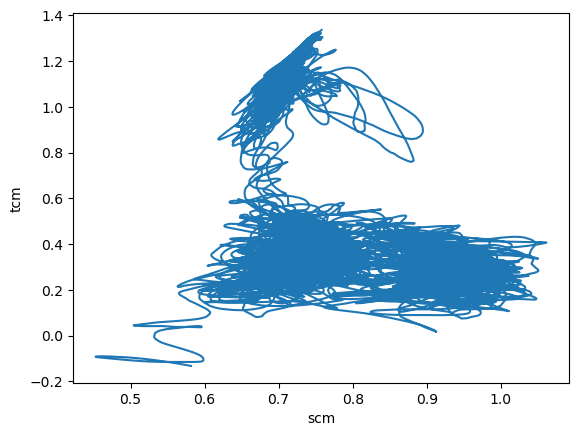

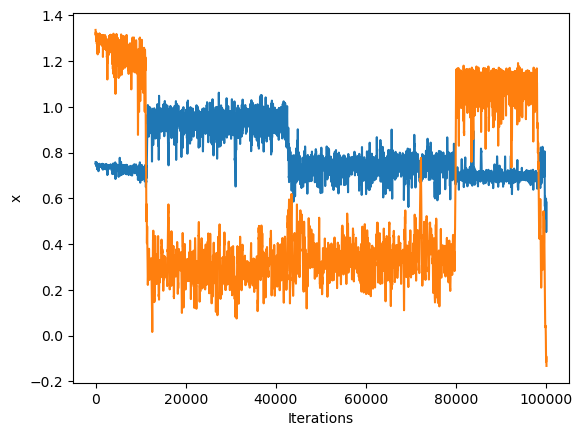

In [ ]:
traj = read('metad3.traj@::')
print(len(traj))


scm = np.zeros(len(traj))
tcm = np.zeros(len(traj))

# Define an array to store the temperature at each step
temperatures = np.zeros(len(traj))
# Define an array to store the energy at each step
energy = np.zeros(len(traj))
kin = np.zeros(len(traj))
pot = np.zeros(len(traj))

for i,snap in enumerate(traj):
    #print(i)
    #print(snap.calc)
    xyz = snap.get_positions()
    scm[i],tcm[i] =_cvs_moments(xyz,cutoff=1.5)
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
    
plot_2d_bias(trajectory=[scm,tcm],pic_name='Metadyn_biase.png')
plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(scm)
plt.plot(tcm)
#plt.savefig('X_movement_DW_C.png')

In [ ]:
import matplotlib.pyplot as plt
import cmocean.cm as cmo
import numpy as np
import subprocess


# Reconstruct the free energy from HILLS using the plumed tool "sum_hills" :
p = subprocess.Popen("plumed sum_hills --hills test3.txt --outfile fes.dat" 
                     " --bin 300,300 --min 0.3,-0.35 --max 1.2,1.56",
                     shell=True, stdout=subprocess.PIPE)
p.wait()




terminate called after throwing an instance of 'PLMD::Plumed::ExceptionError'
  what():  
+++ PLUMED error
+++ at KernelFunctions.cpp:157, function void PLMD::KernelFunctions::setData(const std::vector<double>&, const std::vector<double>&, const string&, const string&, const double&)
+++ message follows +++
stretched-gaussian is an invalid kernel type

Aborted (core dumped)


134

In [ ]:
# Import free energy and reshape with the number of bins defined in the
# reconstruction process.
scm = np.loadtxt('fes.dat', usecols=0).reshape(301, 301)#was 201 everywhere
tcm = np.loadtxt('fes.dat', usecols=1).reshape(301, 301)
fes = np.loadtxt('fes.dat', usecols=2).reshape(301, 301)

# Plot
fig, ax = plt.subplots(figsize=(10, 10))

# Plot free energy surface
im = ax.contourf(scm, tcm, fes, 10, cmap=cmo.tempo_r)
cp = ax.contour(scm, tcm, fes, 10,
                linestyles='-', colors='darkgray', linewidths=1.3)

# Plot parameters
#ax.set_xlabel('SCM', fontsize=40)
#ax.set_ylabel('TCM', fontsize=40)
ax.tick_params(axis='y', labelsize=32)
ax.tick_params(axis='x', labelsize=32)
cbar = fig.colorbar(im, ax=ax)
#cbar.set_label(label=r'FES[$\epsilon$]', fontsize=40)
cbar.ax.tick_params(labelsize=38)
#plt.scatter()
plt.tight_layout()
plt.savefig('biASE_plot.png',dpi=300)
plt.show()

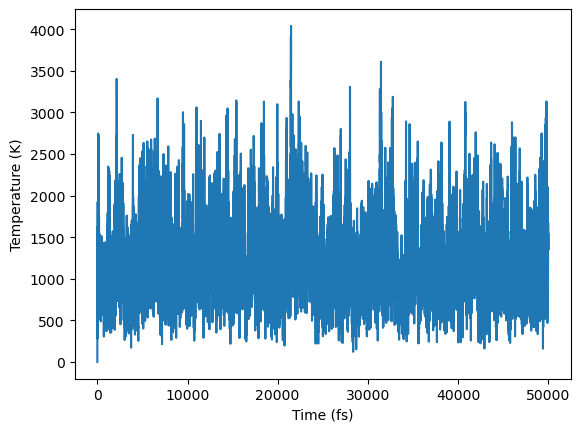

1200.5600283694287


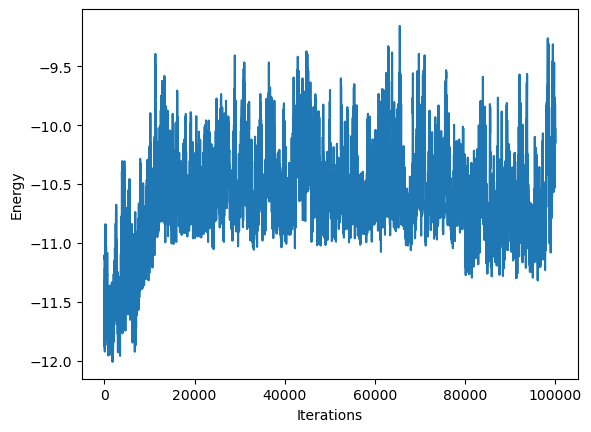

In [ ]:
# Plot the temperature as a function of time
timestep = .5*units.fs
time_ = np.arange(len(traj)) * timestep / units.fs
plt.plot(time_, temperatures)#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.savefig('NVT_DW_temp.png')
plt.show()
print(np.average(np.array(temperatures)))


plt.xlabel('Iterations')
plt.ylabel('Energy')
#plt.plot(kin)
plt.plot(pot)
plt.savefig('E_BIASE_METAD.png')
#plt.plot(energy)

In [ ]:
traj = read('MTD.traj@::10')
print(len(traj))


scm = np.zeros(len(traj))
tcm = np.zeros(len(traj))

# Define an array to store the temperature at each step
temperatures = np.zeros(len(traj))
# Define an array to store the energy at each step
energy = np.zeros(len(traj))
kin = np.zeros(len(traj))
pot = np.zeros(len(traj))

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    scm[i],tcm[i] =_cvs_moments(xyz,cutoff=1.5)
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
    
plot_2d_bias(trajectory=[scm,tcm],pic_name='PLUMED_METAD.png')
plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(scm)
plt.plot(tcm)
plt.savefig('PLUMED_METAD_coordinates.png')

TypeError: FixedPlane.__init__() got an unexpected keyword argument 'a'

In [ ]:
plt.xlabel('Iterations')
plt.ylabel('Energy')
#plt.plot(kin)
#plt.plot(pot)
plt.savefig('E_PLUMED_METAD.png')
plt.plot(energy)

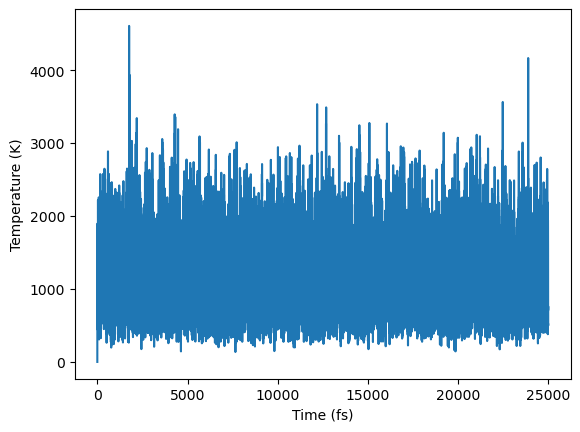

1167.4143058790928


In [ ]:
# Plot the temperature as a function of time
timestep = .5*units.fs
time_ = np.arange(len(traj)) * timestep / units.fs
plt.plot(time_, temperatures)#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')

plt.show()

print(np.average(np.array(temperatures)))

In [ ]:
from ase.md.andersen import Andersen
timestep = 0.005
#.5 * units.fs
atoms = read('isomer.xyz')
print(_cvs_moments(atoms.get_positions(), cutoff=1.5))
print(atoms.get_velocities())
cons = [FixedPlane(i, [0, 0, 1]) for i in range(7)]
atoms.set_constraint(cons)
atoms.set_masses([1, 1, 1, 1, 1, 1, 1])
atoms.calc = LennardJones(rc=2.5, r0=3.0)

dyn = Langevin(atoms, timestep, temperature_K=0.1/units.kB, friction=1, trajectory='UnbiasMD.traj',fixcm=False) #Andersen(atoms, timestep, temperature_K=0.1/units.kB, andersen_prob=0.1, trajectory='UnbiasMD.traj',fixcm=False) #
N_steps = int(1000000)
dyn.run(N_steps) 

(DeviceArray(0.7579546, dtype=float32), DeviceArray(1.3357965, dtype=float32))
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]


True

1000001


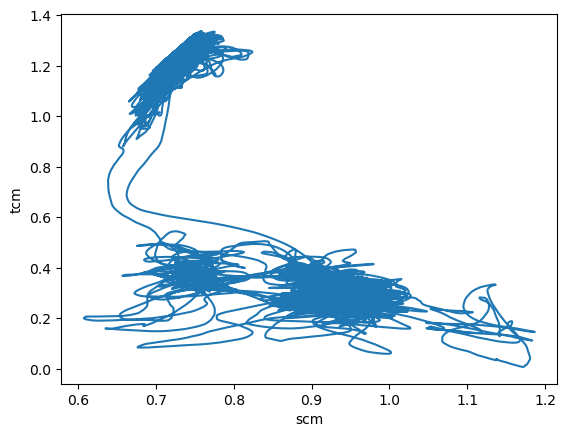

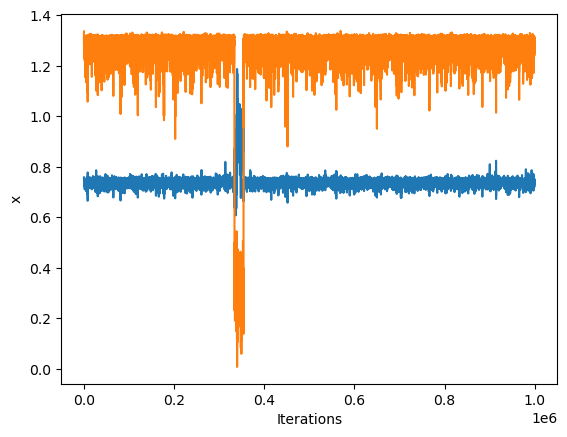

In [ ]:
traj = Trajectory('UnbiasMD.traj')
print(len(traj))


scm = np.zeros(len(traj))
tcm = np.zeros(len(traj))

# Define an array to store the temperature at each step
temperatures = np.zeros(len(traj))
# Define an array to store the energy at each step
energy = np.zeros(len(traj))
kin = np.zeros(len(traj))
pot = np.zeros(len(traj))

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    scm[i],tcm[i] =_cvs_moments(xyz,cutoff=1.5)
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
    
    
plot_2d_bias(trajectory=[scm,tcm],pic_name='MD_langevin.png')

plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(scm)
plt.plot(tcm)
#plt.savefig('X_movement_DW_C.png')

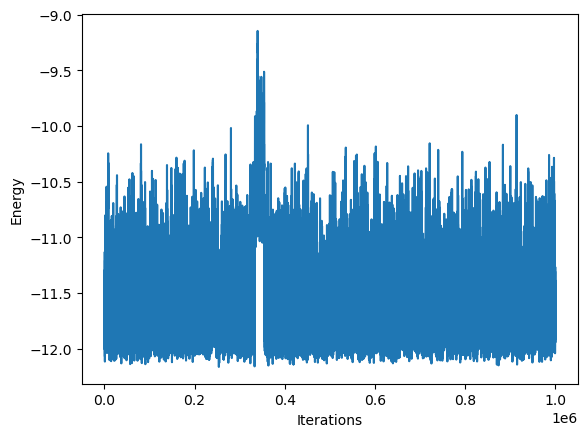

In [ ]:
plt.xlabel('Iterations')
plt.ylabel('Energy')
#plt.plot(kin)
plt.plot(pot)
#plt.plot(energy)
plt.savefig('E_MD_langevin.png')

In [ ]:
from ase.calculators.plumed import Plumed

In [ ]:
timestep = 0.005
ps = 1000 * units.fs

setup = [""]#f"UNITS LENGTH=A TIME={1/ps} ENERGY={units.mol/units.kJ}"]
'''setup = [f"UNITS LENGTH=A TIME={1/ps} ENERGY={units.mol/units.kJ}",
         "COM ATOMS=1-7 LABEL=com",
         "DISTANCE ATOMS=1,com LABEL=d1",
         "UPPER_WALLS ARG=d1 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=2,com LABEL=d2",
         "UPPER_WALLS ARG=d2 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=3,com LABEL=d3",
         "UPPER_WALLS ARG=d3 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=4,com LABEL=d4",
         "UPPER_WALLS ARG=d4 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=5,com LABEL=d5",
         "UPPER_WALLS ARG=d5 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=6,com LABEL=d6",
         "UPPER_WALLS ARG=d6 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=7,com LABEL=d7",
         "UPPER_WALLS ARG=d7 AT=2.0 KAPPA=100.",
         "c1: COORDINATIONNUMBER SPECIES=1-7 MOMENTS=2-3" +
         " SWITCH={RATIONAL R_0=1.5 NN=8 MM=16}",
         "METAD ARG=c1.* HEIGHT=0.05 PACE=500000 " +
         "SIGMA=0.1,0.1 GRID_MIN=-1.5,-1.5 GRID_MAX=2.5,2.5" +
         " GRID_BIN=500,500 BIASFACTOR=5 FILE=HILLS"]'''

atoms = read('isomer.xyz') #read('metad.traj@::10')[200]#
cons = [FixedPlane(i, [0, 0, 1]) for i in range(7)]
atoms.set_constraint(cons)
atoms.set_masses([1, 1, 1, 1, 1, 1, 1])

atoms.calc = Plumed(calc=LennardJones(rc=2.5, r0=3.),
                    input=setup,
                    timestep=timestep,
                    atoms=atoms,)
                    #kT=1.0)

dyn = Andersen(atoms, timestep, temperature_K=0.1/units.kB, andersen_prob=0.1, fixcm=False, trajectory='PLUMED_UnbiasMD.traj')  #Langevin(atoms, timestep, temperature_K=0.1/units.kB, friction=1, fixcm=False, trajectory='PLUMED_UnbiasMD.traj') 
dyn.run(10000)


+++ Loading the PLUMED kernel runtime +++
+++ PLUMED_KERNEL="/home/goennheimer/plumed-2.8.2/src/lib/libplumedKernel.so" +++


True

10001


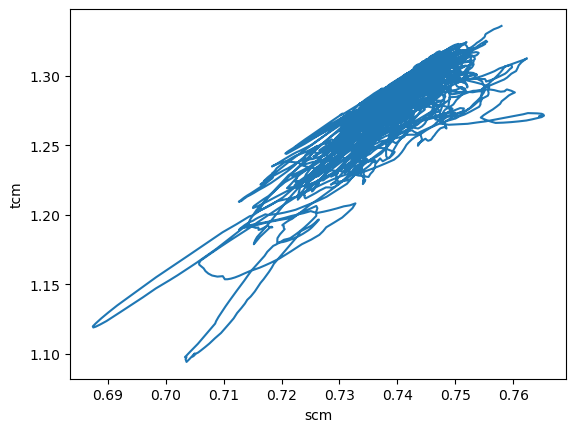

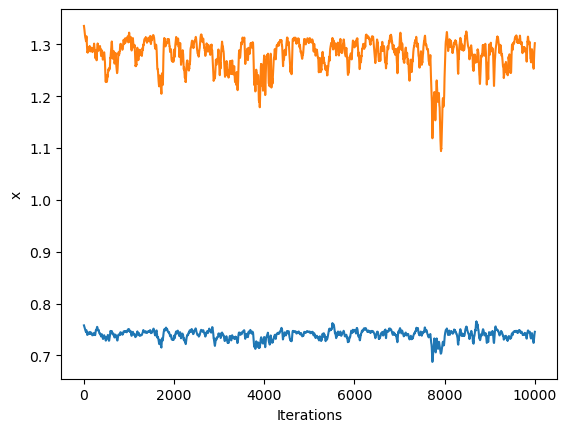

In [ ]:
traj = read('PLUMED_UnbiasMD.traj@::1')
print(len(traj))


scm = np.zeros(len(traj))
tcm = np.zeros(len(traj))

# Define an array to store the temperature at each step
temperatures = np.zeros(len(traj))
# Define an array to store the energy at each step
energy = np.zeros(len(traj))
kin = np.zeros(len(traj))
pot = np.zeros(len(traj))

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    scm[i],tcm[i] =_cvs_moments(xyz,cutoff=1.5)
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
    
    
plot_2d_bias(trajectory=[scm,tcm],pic_name='MD_PLUMED.png')

plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(scm)
plt.plot(tcm)
#plt.savefig('X_movement_DW_C.png')

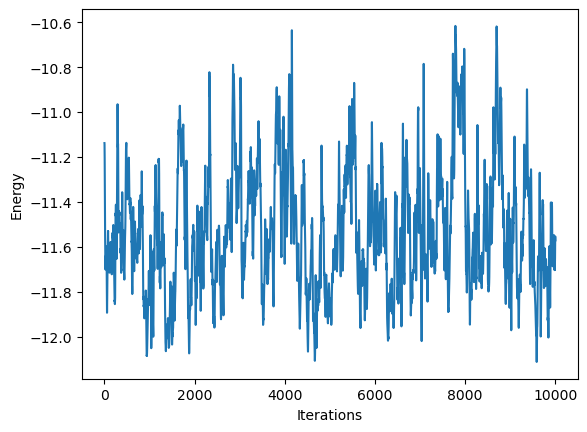

In [ ]:
plt.xlabel('Iterations')
plt.ylabel('Energy')
#plt.plot(kin)
plt.plot(pot)
#plt.plot(energy)
plt.savefig('E_MD_PLUMED.png')

In [ ]:

timestep = 0.005
ps = 1000 * units.fs

setup = [""]#f"UNITS LENGTH=A TIME={1/ps} ENERGY={units.mol/units.kJ}"]


atoms = read('isomer.xyz') #read('metad.traj@::10')[200]#
cons = [FixedPlane(i, [0, 0, 1]) for i in range(7)]
atoms.set_constraint(cons)
atoms.set_masses([1, 1, 1, 1, 1, 1, 1])

atoms.calc = Plumed(calc=LennardJones(rc=2.5, r0=3.),
                    input=setup,
                    timestep=timestep,
                    atoms=atoms,
                    kT=0.1)

dyn = VelocityVerlet(atoms, timestep=timestep, trajectory='PLUMED_UnbiasMD_const_E.traj')# Langevin(atoms, timestep, temperature_K=0.1/units.kB, friction=1, fixcm=False, trajectory='PLUMED_UnbiasMD.traj')

dyn.run(10000)



PLUMED: Cache line size: 512
PLUMED: Number of atoms: 7
PLUMED: File suffix: 
PLUMED: Timestep: 0.000051
PLUMED: KbT: 9.648533
PLUMED: Relevant bibliography:
PLUMED:   [1] The PLUMED consortium, Nat. Methods 16, 670 (2019)
PLUMED:   [2] Tribello, Bonomi, Branduardi, Camilloni, and Bussi, Comput. Phys. Commun. 185, 604 (2014)
PLUMED: Please read and cite where appropriate!
PLUMED: Finished setup
PLUMED:                                               Cycles        Total      Average      Minimum      Maximum
PLUMED:                                                    1     0.004897     0.004897     0.004897     0.004897
PLUMED: 1 Prepare dependencies                          1001     0.000154     0.000000     0.000000     0.000001
PLUMED:                                               Cycles        Total      Average      Minimum      Maximum
PLUMED:                                                    1     0.005069     0.005069     0.005069     0.005069
PLUMED: 1 Prepare dependencies      

+++ Loading the PLUMED kernel runtime +++
+++ PLUMED_KERNEL="/home/goennheimer/plumed-2.8.2/src/lib/libplumedKernel.so" +++


True

10001


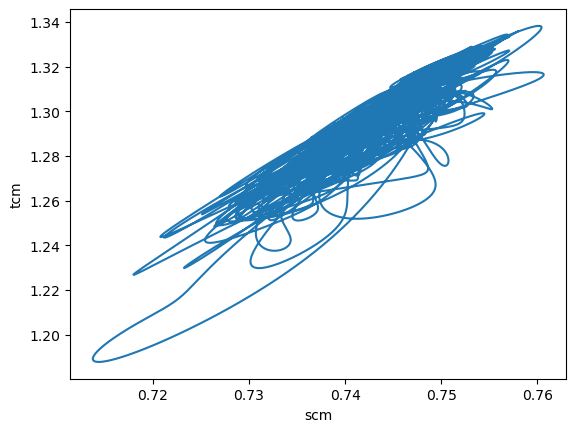

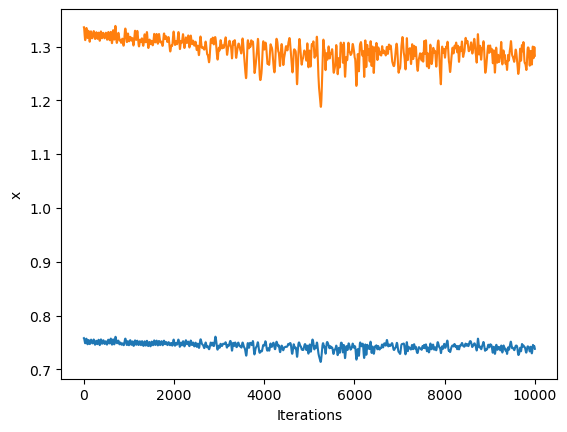

In [ ]:
traj = read('PLUMED_UnbiasMD_const_E.traj@::1')
print(len(traj))


scm = np.zeros(len(traj))
tcm = np.zeros(len(traj))

# Define an array to store the temperature at each step
temperatures = np.zeros(len(traj))
# Define an array to store the energy at each step
energy = np.zeros(len(traj))
kin = np.zeros(len(traj))
pot = np.zeros(len(traj))

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    scm[i],tcm[i] =_cvs_moments(xyz,cutoff=1.5)
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
    
    
plot_2d_bias(trajectory=[scm,tcm],pic_name='MD_PLUMED_const_E.png')

plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(scm)
plt.plot(tcm)
#plt.savefig('X_movement_DW_C.png')



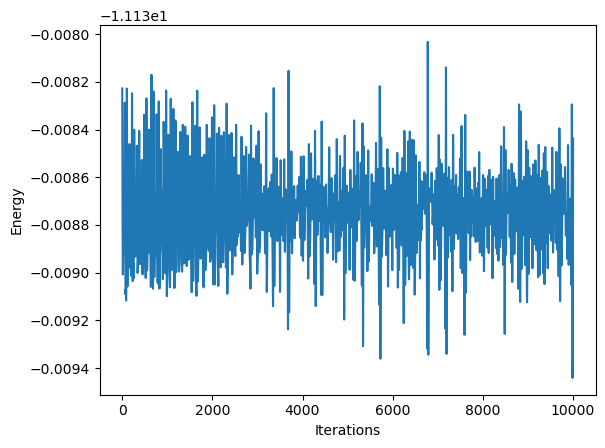

In [ ]:
plt.xlabel('Iterations')
plt.ylabel('Energy')
#plt.plot(kin)
#plt.plot(pot)
plt.plot(energy)
plt.savefig('E_MD_PLUMED_const_E.png')

In [ ]:

timestep = 0.005
ps = 1000 * units.fs

setup = [""]#f"UNITS LENGTH=A TIME={1/ps} ENERGY={units.mol/units.kJ}"]


atoms = read('isomer.xyz') #read('metad.traj@::10')[200]#
cons = [FixedPlane(i, [0, 0, 1]) for i in range(7)]
atoms.set_constraint(cons)
atoms.set_masses([1, 1, 1, 1, 1, 1, 1])

atoms.calc = LennardJones(rc=2.5, r0=3.)

dyn = VelocityVerlet(atoms, timestep=timestep, trajectory='UnbiasMD_const_E.traj')# Langevin(atoms, timestep, temperature_K=0.1/units.kB, friction=1, fixcm=False, trajectory='PLUMED_UnbiasMD.traj')

dyn.run(10000)


True

10001


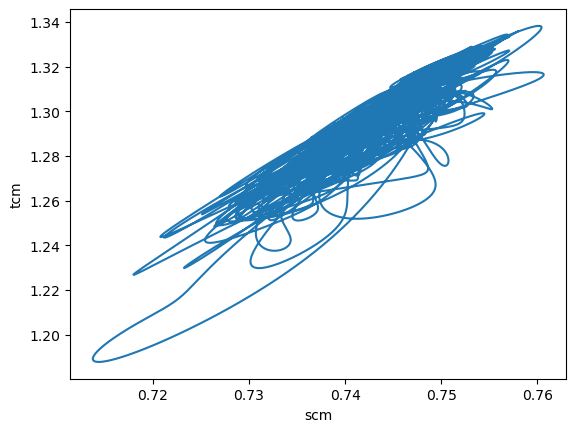

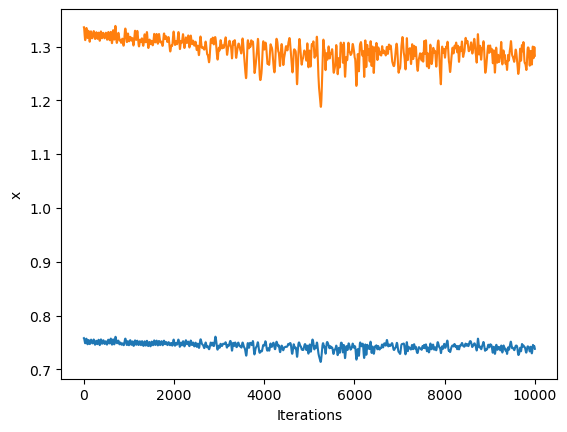

In [ ]:
traj = read('UnbiasMD_const_E.traj@::1')
print(len(traj))


scm = np.zeros(len(traj))
tcm = np.zeros(len(traj))

# Define an array to store the temperature at each step
temperatures = np.zeros(len(traj))
# Define an array to store the energy at each step
energy = np.zeros(len(traj))
kin = np.zeros(len(traj))
pot = np.zeros(len(traj))

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    scm[i],tcm[i] =_cvs_moments(xyz,cutoff=1.5)
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
    
    
plot_2d_bias(trajectory=[scm,tcm],pic_name='MD_const_E.png')

plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(scm)
plt.plot(tcm)
#plt.savefig('X_movement_DW_C.png')



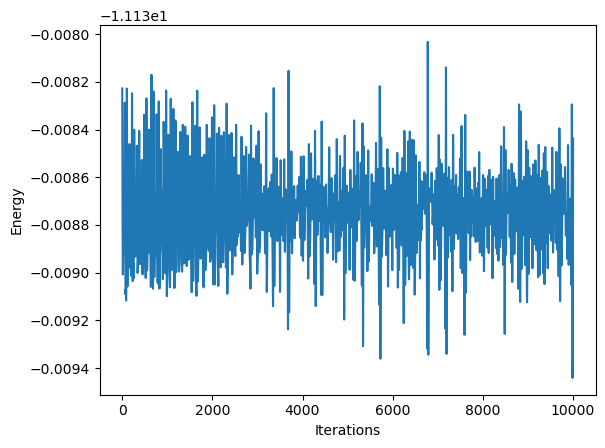

In [ ]:
plt.xlabel('Iterations')
plt.ylabel('Energy')
#plt.plot(kin)
#plt.plot(pot)
plt.plot(energy)
plt.savefig('E_MD_const_E.png')

In [ ]:
traj = read('metad.traj@::10')#read('isomer.xyz')
for atoms in traj[:10]:
    atoms.constraints


In [ ]:
timestep = 0.005
ps = 1000 * units.fs


setup = [f"UNITS LENGTH=A TIME={1/ps} ENERGY={units.mol/units.kJ}",
         "COM ATOMS=1-7 LABEL=com",
         "DISTANCE ATOMS=1,com LABEL=d1",
         "UPPER_WALLS ARG=d1 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=2,com LABEL=d2",
         "UPPER_WALLS ARG=d2 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=3,com LABEL=d3",
         "UPPER_WALLS ARG=d3 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=4,com LABEL=d4",
         "UPPER_WALLS ARG=d4 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=5,com LABEL=d5",
         "UPPER_WALLS ARG=d5 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=6,com LABEL=d6",
         "UPPER_WALLS ARG=d6 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=7,com LABEL=d7",
         "UPPER_WALLS ARG=d7 AT=2.0 KAPPA=100.",
         "c1: COORDINATIONNUMBER SPECIES=1-7 MOMENTS=2-3" +
         " SWITCH={RATIONAL R_0=1.5 NN=8 MM=16}",
         "METAD ARG=c1.* HEIGHT=0.05 PACE=500 " +
         "SIGMA=0.1,0.1 GRID_MIN=-1.5,-1.5 GRID_MAX=2.5,2.5" +
         " GRID_BIN=500,500 BIASFACTOR=5 FILE=HILLS"]

atoms = read('metad.traj@::10')[200]#read('isomer.xyz')
cons = [FixedPlane(i, [0, 0, 1]) for i in range(7)]
atoms.set_constraint(cons)
atoms.set_masses([1, 1, 1, 1, 1, 1, 1])

atoms.calc = Plumed(calc=LennardJones(rc=2.5, r0=3.),
                    input=setup,
                    timestep=timestep,
                    atoms=atoms,
                    kT=0.1)

dyn = Langevin(atoms, timestep, temperature_K=0.1/units.kB, friction=1,
               fixcm=False, trajectory='PLUMED_METAD_otherstart.traj')

dyn.run(100000)


PLUMED: PLUMED is starting
PLUMED: Version: 2.8.2 (git: Unknown) compiled on May  3 2023 at 16:53:06
PLUMED: Please cite these papers when using PLUMED [1][2]
PLUMED: For further information see the PLUMED web page at http://www.plumed.org
PLUMED: Root: /home/goennheimer/plumed-2.8.2/
PLUMED: For installed feature, see /home/goennheimer/plumed-2.8.2//src/config/config.txt
PLUMED: Molecular dynamics engine: ASE
PLUMED: Precision of reals: 8
PLUMED: Running over 1 node
PLUMED: Number of threads: 1
PLUMED: Cache line size: 512
PLUMED: Number of atoms: 7
PLUMED: File suffix: 
PLUMED: Timestep: 0.000051
PLUMED: KbT: 9.648533
PLUMED: Relevant bibliography:
PLUMED:   [1] The PLUMED consortium, Nat. Methods 16, 670 (2019)
PLUMED:   [2] Tribello, Bonomi, Branduardi, Camilloni, and Bussi, Comput. Phys. Commun. 185, 604 (2014)
PLUMED: Please read and cite where appropriate!
PLUMED: Finished setup
PLUMED: PLUMED is starting
PLUMED: Version: 2.8.2 (git: Unknown) compiled on May  3 2023 at 16:53:06


+++ Loading the PLUMED kernel runtime +++
+++ PLUMED_KERNEL="/home/goennheimer/plumed-2.8.2/src/lib/libplumedKernel.so" +++


In [ ]:
traj = read('PLUMED_METAD_otherstart.traj@::1')
print(len(traj))


scm = np.zeros(len(traj))
tcm = np.zeros(len(traj))

# Define an array to store the temperature at each step
temperatures = np.zeros(len(traj))
# Define an array to store the energy at each step
energy = np.zeros(len(traj))
kin = np.zeros(len(traj))
pot = np.zeros(len(traj))

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    scm[i],tcm[i] =_cvs_moments(xyz,cutoff=1.5)
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
    
    
plot_2d_bias(trajectory=[scm,tcm],pic_name='MD_PLUMED.png')

plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(scm)
plt.plot(tcm)
#plt.savefig('X_movement_DW_C.png')

In [ ]:
plt.xlabel('Iterations')
plt.ylabel('Energy')
#plt.plot(kin)
#plt.plot(pot)
plt.plot(energy)
plt.savefig('E_METAD_PLUMED_otherstart.png')

In [ ]:
conda install -c conda-forge asap3

In [ ]:
"""Demonstrates molecular dynamics with constant temperature."""
from ase.lattice.cubic import FaceCenteredCubic
from ase.md.langevin import Langevin
from ase.io.trajectory import Trajectory
from ase import units

from asap3 import EMT  # Way too slow with ase.EMT !
size = 5

T = 1500  # Kelvin

# Set up a crystal
atoms = FaceCenteredCubic(directions=[[1, 0, 0], [0, 1, 0], [0, 0, 1]],
                          symbol="Cu",
                          size=(size, size, size),
                          pbc=False)

# Describe the interatomic interactions with the Effective Medium Theory
atoms.calc = EMT()

# We want to run MD with constant energy using the Langevin algorithm
# with a time step of 5 fs, the temperature T and the friction
# coefficient to 0.02 atomic units.
dyn = Langevin(atoms, 5 * units.fs, T * units.kB, 0.002, trajectory="moldyn3.traj")


def printenergy(a=atoms):  # store a reference to atoms in the definition.
    """Function to print the potential, kinetic and total energy."""
    epot = a.get_potential_energy() / len(a)
    ekin = a.get_kinetic_energy() / len(a)
    print('Energy per atom: Epot = %.3feV  Ekin = %.3feV (T=%3.0fK)  '
          'Etot = %.3feV' % (epot, ekin, ekin / (1.5 * units.kB), epot + ekin))


dyn.attach(printenergy, interval=500)



# Now run the dynamics
dyn.run(1e5)

In [ ]:
atoms.calc =EMT()
# Describe the interatomic interactions with the Effective Medium Theory
'''atoms.calc = Plumed(calc=EMT(),
                    input=setup,
                    timestep=0.005,
                    atoms=atoms,
                    kT=T * units.kB)'''

atoms.get_potential_energy()
emt =LennardJones(rc =2,r0=2)
emt.get_potential_energy(atoms)

In [ ]:
"""Demonstrates molecular dynamics with constant temperature."""
from ase.lattice.cubic import FaceCenteredCubic
from ase.md.langevin import Langevin
from ase.io.trajectory import Trajectory
from ase import units
#from ase.calculators.emt import EMT
from asap3 import EMT  # Way too slow with ase.EMT !
size = 4
setup = ['']
T = 1500  # Kelvin

# Set up a crystal
atoms = FaceCenteredCubic(directions=[[1, 0, 0], [0, 1, 0], [0, 0, 1]],
                          symbol="Cu",
                          size=(size, size, size),
                          pbc=False)

# Describe the interatomic interactions with the Effective Medium Theory
atoms.calc = Plumed(calc=EMT(),
                    input=setup,
                    timestep=0.005,
                    atoms=atoms,
                    kT=T * units.kB)

# We want to run MD with constant energy using the Langevin algorithm
# with a time step of 5 fs, the temperature T and the friction
# coefficient to 0.02 atomic units.
dyn = Langevin(atoms, 5 * units.fs, T * units.kB, 0.002, trajectory="moldyn3_plumed.traj")


def printenergy(a=atoms):  # store a reference to atoms in the definition.
    """Function to print the potential, kinetic and total energy."""
    epot = a.get_potential_energy() / len(a)
    ekin = a.get_kinetic_energy() / len(a)
    print('Energy per atom: Epot = %.3feV  Ekin = %.3feV (T=%3.0fK)  '
          'Etot = %.3feV' % (epot, ekin, ekin / (1.5 * units.kB), epot + ekin))


dyn.attach(printenergy, interval=500)



# Now run the dynamics
dyn.run(1e5)

In [ ]:
header1 = "Header Line 1"
header2 = "Header Line 2"
header3 = "Header Line 3"

list1 = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
list2 = [11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
list3 = [21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
list4 = [31, 32, 33, 34, 35, 36, 37, 38, 39, 40]

# Create the content for the file
content = f"{header1}\n{header2}\n{header3}\n"
content += "List1\tList2\tList3\tList4\n"

for i in range(10):
    content += f"{list1[i]}\t{list2[i]}\t{list3[i]}\t{list4[i]}\n"

# Save the content to a .txt file
filename = "table_data.txt"
with open(filename, "w") as file:
    file.write(content)

print(f"The file '{filename}' has been created.")


The file 'table_data.txt' has been created.
